# Final model evaluation on the untouched test set

This notebook loads the frozen feature list and the final models saved by `model_development_revision.ipynb` for the split named by `SPLIT_SCHEME`. Models are not retrained here, and no hyperparameter optimization or feature selection is performed.

Predictions are generated for the full test set for the `L`, `H`, and `All` models. Metrics are reported overall and separately for low- and high-MP compounds.

In [32]:
from pathlib import Path
import json
import joblib
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / '0_data' / 'outputs' / 'combined_data.parquet').is_file():
    PROJECT_ROOT = PROJECT_ROOT.parent
if not (PROJECT_ROOT / '0_data' / 'outputs' / 'combined_data.parquet').is_file():
    raise FileNotFoundError('Run this notebook from the repository root or a project subdirectory.')

SPLIT_SCHEME = 'stereo_cleaned'  # folder written by 1_data_split/data_split.ipynb
FEATURE_VARIANT = 'correlation_selected'  # the feature set from feature_engineering.ipynb
TRAINING_VARIANT = 'full'  # full, low_MP_undersampled, or balanced_low_high
MODEL_TYPES = ['LGB']
FEATURE_ROOT = PROJECT_ROOT / '2_feature_engineering' / 'outputs' / SPLIT_SCHEME
if FEATURE_VARIANT != 'correlation_selected':
    raise ValueError(f'Unsupported FEATURE_VARIANT: {FEATURE_VARIANT}')
SELECTED_DIR = FEATURE_ROOT / 'selected_features'
FEATURE_LIST_PATH = FEATURE_ROOT / 'selected_features.csv'
if TRAINING_VARIANT == 'low_MP_undersampled':
    TEST_PATH = FEATURE_ROOT / 'low_MP_undersampled' / 'test_full.parquet'
    MODEL_RUN_NAME = 'low_MP_undersampled'
    DATA_TYPES = ['L']
elif TRAINING_VARIANT == 'balanced_low_high':
    # The test set remains the original full population.
    TEST_PATH = SELECTED_DIR / 'test_selected_features.parquet'
    MODEL_RUN_NAME = 'balanced_low_high'
    DATA_TYPES = ['L', 'H', 'All']
elif TRAINING_VARIANT == 'full':
    TEST_PATH = SELECTED_DIR / 'test_selected_features.parquet'
    MODEL_RUN_NAME = FEATURE_VARIANT
    DATA_TYPES = ['L', 'H', 'All']
else:
    raise ValueError(f'Unsupported TRAINING_VARIANT: {TRAINING_VARIANT}')
MODEL_DIR = PROJECT_ROOT / '3_model_development' / 'revised_models' / SPLIT_SCHEME / MODEL_RUN_NAME
OUTPUT_DIR = PROJECT_ROOT / '4_model_evaluation' / 'outputs' / SPLIT_SCHEME / MODEL_RUN_NAME
PREDICTION_DIR = OUTPUT_DIR / 'predictions'
PREDICTION_DIR.mkdir(parents=True, exist_ok=True)

MP_COLUMN = 'MP'
CLASS_COLUMN = 'MP_class'
FINAL_FIT_MODE = 'train_plus_validation'

print('Split scheme:', SPLIT_SCHEME)
print('Feature variant:', FEATURE_VARIANT)
print('Training variant:', TRAINING_VARIANT)
print('Test input:', TEST_PATH.relative_to(PROJECT_ROOT))
print('Model directory:', MODEL_DIR.relative_to(PROJECT_ROOT))
print('Evaluation output directory:', OUTPUT_DIR.relative_to(PROJECT_ROOT))

Split scheme: stereo_cleaned
Feature variant: correlation_selected
Training variant: full
Test input: 2_feature_engineering/outputs/stereo_cleaned/selected_features/test_selected_features.parquet
Model directory: 3_model_development/revised_models/stereo_cleaned/correlation_selected
Evaluation output directory: 4_model_evaluation/outputs/stereo_cleaned/correlation_selected


## Load the frozen test table and feature list

The test table is loaded only in this final evaluation notebook. The explicit feature list prevents metadata from entering the predictor matrix.

In [33]:
if not FEATURE_LIST_PATH.is_file():
    raise FileNotFoundError(f'Missing selected feature list: {FEATURE_LIST_PATH}')

feature_names = pd.read_csv(FEATURE_LIST_PATH)['Feature'].dropna().astype(str).tolist()
test_data = pd.read_parquet(TEST_PATH)

missing_features = sorted(set(feature_names).difference(test_data.columns))
missing_columns = sorted({MP_COLUMN, CLASS_COLUMN}.difference(test_data.columns))
if missing_features or missing_columns:
    raise ValueError(f'test: missing features={missing_features[:5]}, metadata={missing_columns}')
if test_data[feature_names].isna().any().any():
    raise ValueError('test contains NaN values in the selected features.')

print('Test:', test_data.shape)
print('Selected feature count:', len(feature_names))

Test: (55427, 1711)
Selected feature count: 1690


## Define model and regime helpers

The regime helper accepts both the current `low`/`high` labels and the shorthand `L`/`H` labels. Each saved model's metadata must match this notebook's split scheme, training variant, and feature count. Each model predicts every test compound.

In [34]:
def normalized_class(frame):
    labels = frame[CLASS_COLUMN].astype(str).str.strip().str.lower()
    return labels.replace({'l': 'low', 'h': 'high'})

def load_final_model(model_type, regime):
    stem = f'{model_type}_{regime}_{FINAL_FIT_MODE}'
    model_path = MODEL_DIR / f'best_model_{stem}.joblib'
    metadata_path = MODEL_DIR / f'model_metadata_{stem}.json'
    for path in [model_path, metadata_path]:
        if not path.is_file():
            raise FileNotFoundError(f'Missing saved final model file: {path}')
    metadata = json.loads(metadata_path.read_text())
    expected = {'split_scheme': SPLIT_SCHEME, 'training_variant': TRAINING_VARIANT,
                'selected_feature_count': len(feature_names), 'test_used': False}
    mismatched = {key: metadata.get(key) for key, value in expected.items() if metadata.get(key) != value}
    if mismatched:
        raise ValueError(f'{model_path.name} metadata does not match this evaluation: {mismatched}')
    return joblib.load(model_path)

def calculate_metrics(y_true, y_pred):
    return {
        'N_compounds': int(len(y_true)),
        'RMSE': float(np.sqrt(mean_squared_error(y_true, y_pred))),
        'MAE': float(mean_absolute_error(y_true, y_pred)),
        'R2': float(r2_score(y_true, y_pred)) if len(y_true) > 1 else np.nan,
    }

## Evaluate the complete test set

The saved final models are used without modification. No search or refit is performed after the test set is loaded. Test metrics are calculated overall and separately for the low- and high-MP subsets.

In [35]:
prediction_tables = []
metric_rows = []

for model_type in MODEL_TYPES:
    for regime in DATA_TYPES:
        model = load_final_model(model_type, regime)

        # Predict the entire unchanged test table; metrics below are then
        # reported separately for Low, High, and All test subsets.
        predictions = model.predict(test_data[feature_names])
        prediction_columns = [column for column in ['SMILES', MP_COLUMN, CLASS_COLUMN, 'Source'] if column in test_data.columns]
        prediction_table = test_data[prediction_columns].copy()
        prediction_table['MP_pred'] = predictions
        prediction_table['Model_type'] = model_type
        prediction_table['Training_regime'] = regime
        prediction_table.to_parquet(PREDICTION_DIR / f'predictions_{model_type}_{regime}.parquet', index=False)
        prediction_tables.append(prediction_table)

        test_labels = normalized_class(test_data)
        for evaluation_subset, subset_mask in {
            'low': test_labels == 'low',
            'high': test_labels == 'high',
            'all': pd.Series(True, index=test_data.index),
        }.items():
            metrics = calculate_metrics(test_data.loc[subset_mask, MP_COLUMN], predictions[subset_mask.to_numpy()])
            metric_rows.append({'Model_type': model_type, 'Training_regime': regime, 'Evaluation_subset': evaluation_subset, **metrics})

all_predictions = pd.concat(prediction_tables, ignore_index=True)
all_predictions.to_parquet(OUTPUT_DIR / 'all_test_predictions.parquet', index=False)
metrics_table = pd.DataFrame(metric_rows)
metrics_table.to_csv(OUTPUT_DIR / 'evaluation_metrics.csv', index=False)
display(metrics_table)
print(f'Saved predictions and metrics to {OUTPUT_DIR.relative_to(PROJECT_ROOT)}')

,Model_type,Training_regime,Evaluation_subset,N_compounds,RMSE,MAE,R2
0,LGB,L,low,51145,33.528221,25.833518,0.601294
1,LGB,L,high,4282,83.118989,76.865793,-9.863262
2,LGB,L,all,55427,39.636239,29.776005,0.605212
3,LGB,H,low,51145,137.437523,126.997302,-5.699499
4,LGB,H,high,4282,21.637905,16.643335,0.263810
5,LGB,H,all,55427,132.158891,118.471932,-3.389068
6,LGB,All,low,51145,34.220717,26.009317,0.584654
7,LGB,All,high,4282,58.186455,46.697036,-4.323577
8,LGB,All,all,55427,36.635315,27.607542,0.662729


Saved predictions and metrics to 4_model_evaluation/outputs/stereo_cleaned/correlation_selected


In [36]:
config = {
    'split_scheme': SPLIT_SCHEME,
    'feature_variant': FEATURE_VARIANT,
    'training_variant': TRAINING_VARIANT,
    'model_run_name': MODEL_RUN_NAME,
    'model_types': MODEL_TYPES,
    'training_regimes': DATA_TYPES,
    'final_fit_mode': FINAL_FIT_MODE,
    'test_used_for': 'final_evaluation_only',
    'feature_list': str(FEATURE_LIST_PATH.relative_to(PROJECT_ROOT)),
    'feature_count': len(feature_names),
    'model_directory': str(MODEL_DIR.relative_to(PROJECT_ROOT)),
    'test_input': str(TEST_PATH.relative_to(PROJECT_ROOT)),
}
(OUTPUT_DIR / 'evaluation_config.json').write_text(json.dumps(config, indent=2))
print('Evaluation configuration saved.')

Evaluation configuration saved.


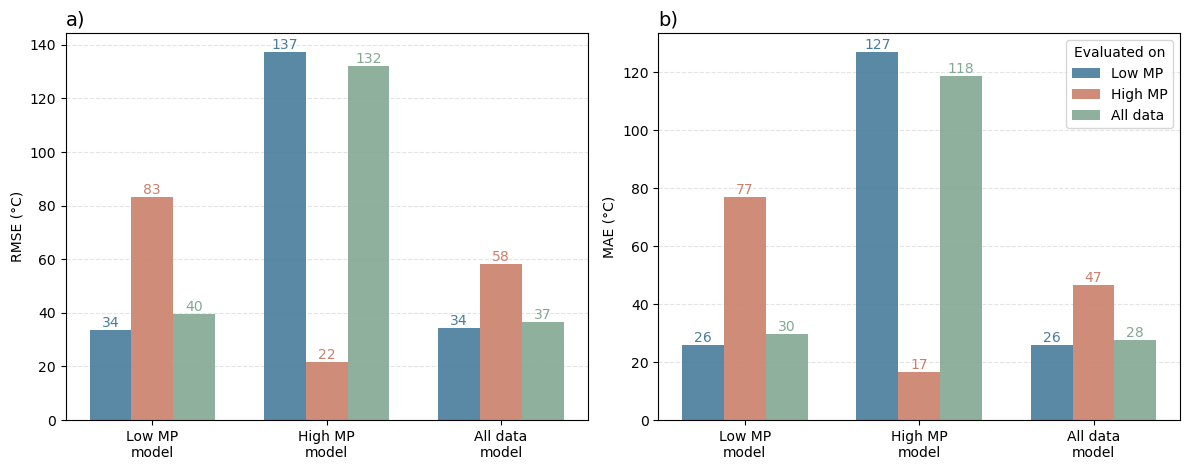

In [41]:
# Compare training regimes (x-axis) and evaluation subsets (bar colors).
import matplotlib.pyplot as plt
plot_data = metrics_table.copy()
regime_order = [regime for regime in ['L', 'H', 'All'] if regime in DATA_TYPES]
evaluation_order = [('low', 'Low MP', '#477C9B'), ('high', 'High MP', '#CA806B'), ('all', 'All data', '#83A891')]
x_labels = {'L': 'Low MP\nmodel', 'H': 'High MP\nmodel', 'All': 'All data\nmodel'}
x = np.arange(len(regime_order))
bar_width = 0.24
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
for ax, metric, panel_label in zip(axes, ['RMSE', 'MAE'], ['a)', 'b)']):
    for bar_index, (subset_name, subset_label, color) in enumerate(evaluation_order):
        values = []
        for regime in regime_order:
            row = plot_data[(plot_data['Training_regime'] == regime) & (plot_data['Evaluation_subset'] == subset_name)]
            if len(MODEL_TYPES) == 1:
                row = row[row['Model_type'] == MODEL_TYPES[0]]
            values.append(float(row.iloc[0][metric]) if not row.empty else np.nan)
        bars = ax.bar(x + (bar_index - 1) * bar_width, values, bar_width, label=subset_label, color=color, alpha=0.9)
        for bar, value in zip(bars, values):
            if np.isfinite(value):
                ax.text(bar.get_x() + bar.get_width() / 2, value, f'{value:.0f}', ha='center', va='bottom', fontsize=10, color=color)
    ax.set_title(panel_label, loc='left', fontsize=14)
    ax.set_ylabel(f'{metric} (°C)')
    ax.set_xticks(x)
    ax.set_xticklabels([x_labels[regime] for regime in regime_order])
    ax.grid(axis='y', linestyle='--', alpha=0.35)
    ax.set_axisbelow(True)
axes[1].legend(title='Evaluated on', loc='upper right')
#fig.suptitle(f'Test-set performance by training regime: {MODEL_RUN_NAME}', y=1.02)
fig.tight_layout()
plt.show()

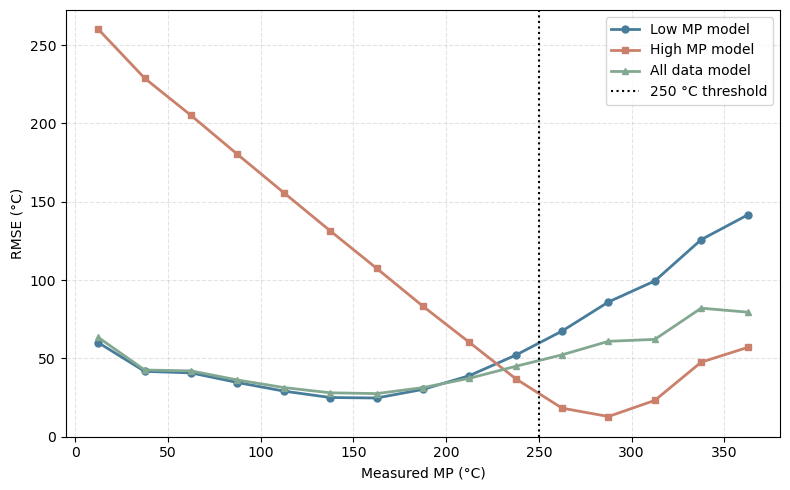

,,L,H,All,N_compounds
MP_bin,MP_bin_center,,,,
"[0.0, 25.0)",12.5,60.0,260.0,63.4,277
"[25.0, 50.0)",37.5,41.7,228.8,42.6,1443
"[50.0, 75.0)",62.5,40.7,205.1,42.0,4227
"[75.0, 100.0)",87.5,34.6,180.2,36.2,6308
"[100.0, 125.0)",112.5,29.1,155.7,31.4,7630
"[125.0, 150.0)",137.5,25.0,131.4,28.0,8396
"[150.0, 175.0)",162.5,24.7,107.5,27.5,7819
"[175.0, 200.0)",187.5,30.2,83.3,31.4,6565
"[200.0, 225.0)",212.5,39.0,60.2,37.3,5087


In [42]:
# RMSE of each model within 25 °C bins of the measured MP (whole test set).
import matplotlib.pyplot as plt
MP_BIN_WIDTH = 25
MIN_BIN_COUNT = 20  # bins with fewer test compounds are not plotted
high_threshold = test_data.loc[normalized_class(test_data) == 'high', MP_COLUMN].min()
model_styles = {'L': ('Low MP model', '#477C9B', 'o'), 'H': ('High MP model', '#CA806B', 's'), 'All': ('All data model', '#83A891', '^')}
bin_edges = np.arange(np.floor(test_data[MP_COLUMN].min() / MP_BIN_WIDTH) * MP_BIN_WIDTH,
                      test_data[MP_COLUMN].max() + MP_BIN_WIDTH, MP_BIN_WIDTH)
binned_rows = []
for (model_type, regime), frame in all_predictions.groupby(['Model_type', 'Training_regime'], sort=False):
    mp_bin = pd.cut(frame[MP_COLUMN], bins=bin_edges, right=False)
    squared_error = (frame['MP_pred'] - frame[MP_COLUMN]) ** 2
    for interval, errors in squared_error.groupby(mp_bin, observed=True):
        binned_rows.append({'Model_type': model_type, 'Training_regime': regime, 'MP_bin': str(interval),
                            'MP_bin_center': interval.mid, 'N_compounds': len(errors), 'RMSE': float(np.sqrt(errors.mean()))})
rmse_by_mp = pd.DataFrame(binned_rows)
plotted = rmse_by_mp[rmse_by_mp['N_compounds'] >= MIN_BIN_COUNT]

fig, ax = plt.subplots(figsize=(8, 5))
for regime in [regime for regime in ['L', 'H', 'All'] if regime in DATA_TYPES]:
    label, color, marker = model_styles[regime]
    for model_type in MODEL_TYPES:
        rows = plotted[(plotted['Training_regime'] == regime) & (plotted['Model_type'] == model_type)]
        model_label = label if len(MODEL_TYPES) == 1 else f'{model_type} {label}'
        ax.plot(rows['MP_bin_center'], rows['RMSE'], color=color, marker=marker, linewidth=2, markersize=5, label=model_label)
ax.axvline(high_threshold, color='black', linestyle=':', linewidth=1.5, label=f'{high_threshold:.0f} °C threshold')
ax.set_xlabel('Measured MP (°C)')
ax.set_ylabel('RMSE (°C)')
ax.set_ylim(bottom=0)
ax.grid(linestyle='--', alpha=0.35)
ax.set_axisbelow(True)
ax.legend()
#ax.set_title(f'Test-set RMSE by measured MP ({MP_BIN_WIDTH} °C bins, n ≥ {MIN_BIN_COUNT}): {MODEL_RUN_NAME}')
fig.tight_layout()
# fig.savefig(OUTPUT_DIR / 'rmse_vs_mp.png', dpi=300, bbox_inches='tight')
plt.show()
rmse_by_mp_table = rmse_by_mp.pivot_table(index=['MP_bin', 'MP_bin_center'], columns='Training_regime', values='RMSE', sort=False)
display(rmse_by_mp_table[[regime for regime in ['L', 'H', 'All'] if regime in rmse_by_mp_table.columns]].round(1)
        .join(rmse_by_mp.groupby(['MP_bin', 'MP_bin_center'], sort=False)['N_compounds'].first()).sort_index(level='MP_bin_center'))